In [ ]:
%pip install geopandas

import geopandas as gpd
import matplotlib as mpl

   ---------------------------------------- 0.0/23.8 MB ? eta -:--:--
   --- ------------------------------------ 1.8/23.8 MB 10.8 MB/s eta 0:00:03
   ------ --------------------------------- 3.7/23.8 MB 9.8 MB/s eta 0:00:03
   --------- ------------------------------ 5.5/23.8 MB 9.6 MB/s eta 0:00:02
   ----------- ---------------------------- 7.1/23.8 MB 9.1 MB/s eta 0:00:02
   -------------- ------------------------- 8.7/23.8 MB 8.9 MB/s eta 0:00:02
   ----------------- ---------------------- 10.2/23.8 MB 8.6 MB/s eta 0:00:02
   ------------------ --------------------- 11.3/23.8 MB 8.2 MB/s eta 0:00:02
   --------------------- ------------------ 12.8/23.8 MB 8.1 MB/s eta 0:00:02
   ------------------------ --------------- 14.7/23.8 MB 8.1 MB/s eta 0:00:02
   --------------------------- ------------ 16.5/23.8 MB 8.2 MB/s eta 0:00:01
   ------------------------------ --------- 18.4/23.8 MB 8.4 MB/s eta 0:00:01
   ---------------------------------- ----- 20.4/23.8 MB 8.5 MB/s eta 0:00:0

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [9]:
import os
os.environ.pop("PROJ_LIB", None)

import geopandas as gpd

In [ ]:
import geopandas as gpd

path_to_files = "dane/wulkany/"

# SHP:

shp_v = gpd.read_file(path_to_files+"lw1/lw1.shp")
print(shp_v.head())

# GEOJSON:

geojson_v = gpd.read_file(path_to_files+"lw1.geojson")
print(geojson_v.head())

# GPKG:

gpkg_v = gpd.read_file(path_to_files+"lw1.gpkg")
print(gpkg_v.head())

# CSV:

import pandas as pd
import os
csv_v_raw = pd.read_csv(path_to_files+"lw1.csv")
csv_v = gpd.GeoDataFrame(
    csv_v_raw,
    geometry=gpd.points_from_xy(
        csv_v_raw["x"],
        csv_v_raw["y"]
    ),
    crs="EPSG:4326"
) # Skąd wynika większe skomplikowanie przy csv?

print(csv_v_raw)

    gid               nazwa ostatnia_e               kraj                typ  \
0   830               Ambae       2021            Vanuatu           tarczowy   
1   499              Pavlof       2021  Stany Zjednoczone       stratowulkan   
2   821             Kavachi       2021     Wyspy Salomona           podwodny   
3  1130  Rincon de la Vieja       2021          Kostaryka  mieszane, złożone   
4   469        Great Sitkin       2021  Stany Zjednoczone       stratowulkan   

              rodzaj_eru                     materiał  \
0  erupcja zaobserwowana              bazalt / pikryt   
1  erupcja zaobserwowana  andezyt / andezyt bazaltowy   
2  erupcja zaobserwowana  andezyt / andezyt bazaltowy   
3  erupcja zaobserwowana  andezyt / andezyt bazaltowy   
4  erupcja zaobserwowana  andezyt / andezyt bazaltowy   

                                           tektonika legenda  \
0    strefa subdukcji / skorupa oceaniczna (< 15 km)  Wulkan   
1  strefa subdukcji / skorupa kontynentalna (>25

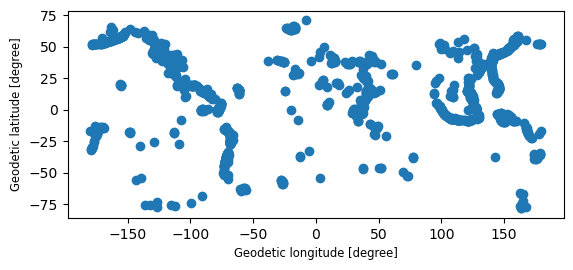

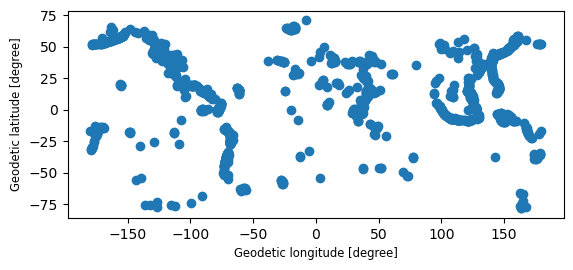

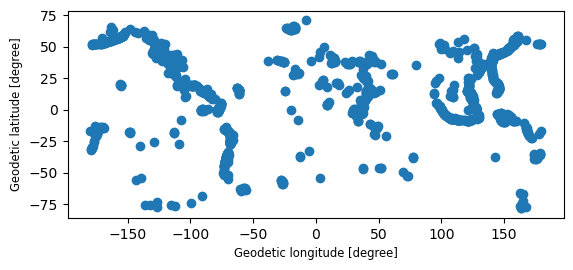

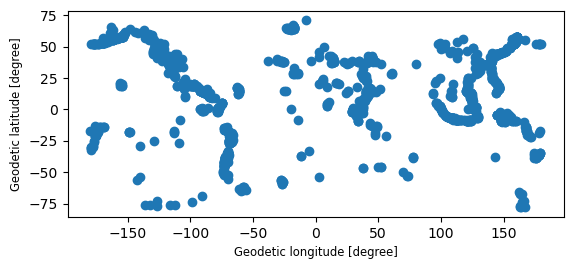

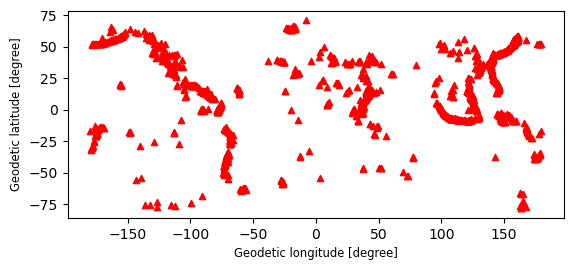

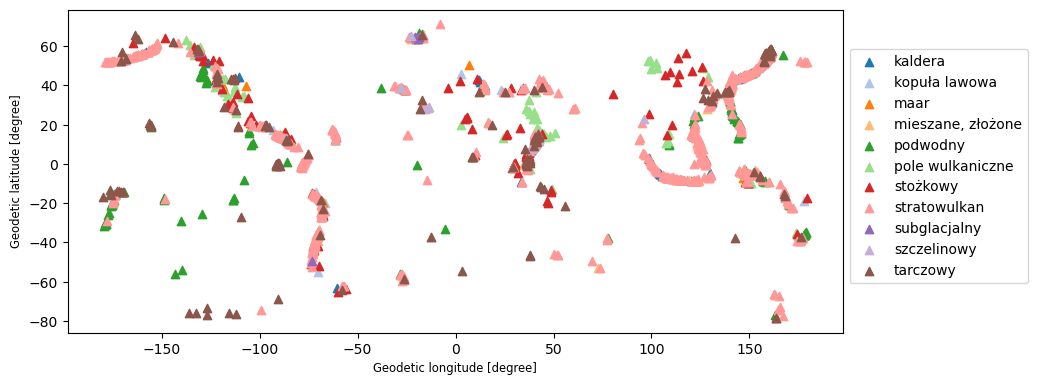

In [5]:
# Źródło danych po poprawnym załadowaniu nie ma już znaczenia dla dalszych operacji
shp_v.plot()
geojson_v.plot()
gpkg_v.plot()
csv_v.plot()

# Oczywiście funkcja plot() przyjmuje wiele możliwych parametrów dot. stylizacji
geojson_v.plot(
    marker="^",
    color="red",
    markersize=20
)

# Do bardziej skomplikowanych zobrazowań, zawierających więcej elementów niż tylko mapę, warto użyć Matplotlib
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

geojson_v.plot(
    marker="^",
    column="typ",
    legend=True,
    ax=ax
)

legend = ax.get_legend()
legend.set_bbox_to_anchor((1, 0.9))

plt.show()

['Point']
['MultiLineString']
['MultiPolygon']
                 nazwa  liczba_poligonow
23              Kanada               284
122         Afganistan               196
68          Grenlandia               143
241  Stany Zjednoczone               137
147          Indonezja               136
27               Chile               123
106           Norwegia                68
123           Filipiny                45
44            Brazylia                40
22           Australia                35
nazwa               Kanada
liczba_poligonow       284
Name: 23, dtype: object


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

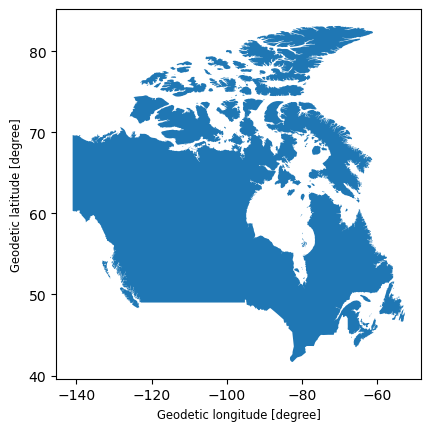

In [7]:
path_to_files = "dane/"

vulcans = geojson_v
rivers = gpd.read_file(path_to_files+"hr1.geojson")
demography = gpd.read_file(path_to_files+"lsp1.geojson")

print(vulcans.geom_type.unique()) # Co się stanie jeśli pominiemy .unique() ?
print(rivers.geom_type.unique())
print(demography.geom_type.unique())
# Czym różni się MultiPoint / MultiLineString / MultiPolygon od Point / LineString / Polygon ?

# Dla Demography, policzmy które kraje w zbiorze składają się z największej ilości poligonów:
demography["liczba_poligonow"] = demography.geometry.apply(lambda geom: len(geom.geoms))

ranking = (
    demography[["nazwa", "liczba_poligonow"]]
    .sort_values("liczba_poligonow", ascending=False)
)

print(ranking[:10])

# Czy 1 miejsce w rankingu rzeczywiście ma aż tyle elementów składowych? Potwierdzmy to sobie wizualnie:

print(ranking.iloc[0])

subGdf = demography.loc[[ranking.iloc[0].name]]
subGdf.plot()

Filtrowanie danych w GeoPandas może mieć charakter przestrzenny jak i nieprzestrzenny. Na ten moment skupmy się na nieprzestrzennym - analogicznie jak w zwykłym Pandas, używając warunków przeszukajmy dane odpowiadając na zadane pytania:

In [8]:
# Wyfiltrujmy tylko te wulkany, których nazwa zaczyna się od litery "E" a następnie obliczmy jaki jest to % wszystkich wulkanów

vulcans_E = vulcans[ vulcans["nazwa"].str.startswith("E") ] # Co zwraca samo vulcans["nazwa"].str.startswith("E") ?
print(vulcans_E.head())

vulcans_count = len(vulcans)
vulcans_E_count = len(vulcans_E)
result = ( vulcans_E_count * 100 ) / vulcans_count

print(f"Wulkanów na literę 'E' jest w zbiorze {vulcans_E_count}. Stanowi to ~{result:.2f}% wszystkich wulkanów.")

# Wyfiltrujmy tylko te rzeki, których długość wynosi ponad 4000 km. Wykorzystajmy do tego zawarte pole w danych "długość", a nie liczoną długość geometrii

print(rivers.długość.head()) # Jaka jest różnica między rivers.długość a dotychczas używanym zapisie rivers["długość"] ?

# Standaryzacja danych:
print(rivers["długość"].isna().sum()) # Czy mamy puste wartości?
rivers["długość_stand"] = rivers["długość"]
rivers["długość_stand"] = rivers["długość_stand"].fillna(0)

rivers["długość_stand"] = (
    rivers["długość_stand"].astype(str)
    .str.replace("km", "", regex=False)
    .str.replace(r"\s+", "", regex=True)
) # Usunięcie białych znaków czy jednostki "km"

rivers["długość_stand"] = rivers["długość_stand"].astype(int)

# Warunek na długość ponad 4000 km:
rivers4000 = rivers[rivers["długość_stand"] > 4000]
rivers4000_count = len(rivers4000)
rivers4000_names_as_text = ", ".join(rivers4000.sort_values("długość_stand", ascending=False)["nazwa"])

# Warto zwrócić uwagę na to jak w GeoPandas / Pandas unikamy klasycznych pętli, zamiast tego wykorzystując pracę bezpośrednio na strukturze danych
# Takie podejście często określamy jako wektoryzację: zamiast ręcznie przetwarzać każdy element, wykonujemy operację na całej serii lub kolumnie
# Przykład z wykorzystaniem pętli:
rivers4000_names2 = []
for river in rivers4000.sort_values("długość_stand", ascending=False)["nazwa"]:
    rivers4000_names2.append(river)
rivers4000_names_as_text2 = ", ".join(rivers4000_names2)
# Pętle nie są oczywiście złe same w sobie - ale znacznie komplikują zapis, a często nawet zmniejszają wydajnosć operacji.
# Jesli to możliwe - starajmy się ich unikać pracując z GeoDataFrame

print(f"Ilość rzek o zadeklarowanej długości ponad 4000 km w zbiorze: {rivers4000_count}. Są to: {rivers4000_names_as_text}")

     gid           nazwa ostatnia_erupcja     kraj           typ  \
18    35          Elbrus               50    Rosja  stratowulkan   
29   106           Ebeko             2018    Rosja  stratowulkan   
70   833             Epi             2004  Vanuatu  stratowulkan   
175   30    Erciyes Dagi      6880 p.n.e.   Turcja  stratowulkan   
200  530  Est, Ile de l'      brak danych  Francja  stratowulkan   

             rodzaj_erupcji                     materiał  \
18         erupcja datowana                        dacyt   
29    erupcja zaobserwowana  andezyt / andezyt bazaltowy   
70    erupcja zaobserwowana              bazalt / pikryt   
175        erupcja datowana                        dacyt   
200  brak dowodów na wybuch              bazalt / pikryt   

                                             tektonika legenda  \
18   strefa subdukcji / skorupa kontynentalna (>25 km)  Wulkan   
29   strefa subdukcji / skorupa kontynentalna (>25 km)  Wulkan   
70     strefa subdukcji / skorup